# ContextLens — Retrieval Depth (K) Experiment

Research question: **does increasing the number of retrieved chunks always improve RAG answer quality?**

This notebook reproduces the K-sweep analysis (`no_rag`, `k1`, `k3`, `k5`, `k10`, `gold`) from the
completed benchmark run `results/benchmark/full-50q-2026-10-12/`. It does not re-run the benchmark
(that needs the local LLM and a live Postgres instance — see the repository README); it loads the
already-recorded `runs.jsonl` and reuses the project's own aggregation code in
`backend/app/research/benchmark.py` so the numbers here match `results/comparison_table.csv` and
`results/figures/` exactly.

To regenerate a fresh run: `python -m backend.app.research.benchmark run` (see README §6).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from backend.app.research.benchmark import aggregate, paired_tests, summarize  # noqa: E402

RUN_ID = "full-50q-2026-10-12"
RUN_DIR = ROOT / "results" / "benchmark" / RUN_ID
RUN_DIR

PosixPath('/Users/tarangkumar/Developer/Personal projects/BIT/ContextLense/results/benchmark/full-50q-2026-10-12')

## Load the raw per-question, per-condition records

In [2]:
latest = {}
with open(RUN_DIR / "runs.jsonl", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            r = json.loads(line)
            latest[(r["question_id"], r["condition"])] = r
records = list(latest.values())
len(records), records[0]["condition"]

(275, 'no_rag')

## Aggregate by condition (reuses `backend.app.research.benchmark.aggregate`)

`aggregate()` and `paired_tests()` are pure functions over the record list — no database or model
connection is needed to analyse an already-completed run.

In [3]:
CONDITION_ORDER = ["no_rag", "k1", "k3", "k5", "k10", "gold"]
by_condition = {c: aggregate([r for r in records if r["condition"] == c]) for c in CONDITION_ORDER}
df = pd.DataFrame(by_condition).T
df.index.name = "condition"
df[["n", "accuracy_normalised_mean", "abstention_rate", "context_fact_recall_mean",
    "claims_lexically_supported_rate", "total_ms_median"]]

,n,accuracy_normalised_mean,abstention_rate,context_fact_recall_mean,claims_lexically_supported_rate,total_ms_median
condition,,,,,,
no_rag,50,0.37,0.0,None,None,3058.51
k1,50,0.32,0.46,0.4567,0.456,6981.44
k3,50,0.51,0.26,0.6807,0.7458,15741.8
k5,50,0.55,0.1,0.7923,0.8727,27192.43
k10,50,0.59,0.1,0.8653,0.9301,51532.35
gold,25,0.72,0.04,0.8707,0.6182,3731.57


## Flat comparison table (same content as `results/comparison_table.csv`)

In [4]:
comparison = pd.read_csv(ROOT / "results" / "comparison_table.csv")
comparison

,condition,label,k,n,accuracy_normalised_mean,abstention_rate,context_fact_recall_mean,context_fact_bearing_precision_mean,gold_page_retrieved_rate,hallucination_rate,claims_lexically_supported_rate,citation_validity_mean,cites_gold_page_rate,total_ms_median,total_ms_mean,retrieval_ms_median,generation_ms_median
0,no_rag,No retrieval,0,50,0.37,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3058.51,3517.7490,0.00,3058.51
1,k1,Top-1,1,50,0.32,0.46,0.4567,0.7800,0.36,0.5440,0.4560,0.9615,0.20,6981.44,8030.6624,97.32,6846.74
2,k3,Top-3,3,50,0.51,0.26,0.6807,0.5867,0.52,0.2542,0.7458,1.0000,0.24,15741.80,18390.2744,39.59,15601.42
3,k5,Top-5,5,50,0.55,0.10,0.7923,0.5720,0.64,0.1273,0.8727,1.0000,0.24,27192.43,27918.2112,60.45,26411.33
4,k10,Top-10,10,50,0.59,0.10,0.8653,0.5000,0.84,0.0699,0.9301,1.0000,0.16,51532.35,53601.9418,92.19,51314.12
5,gold,Gold page (oracle),oracle,25,0.72,0.04,0.8707,1.0000,1.00,0.3818,0.6182,1.0000,0.92,3731.57,4153.4320,0.00,3726.37


## Does accuracy keep improving with K? (H1)

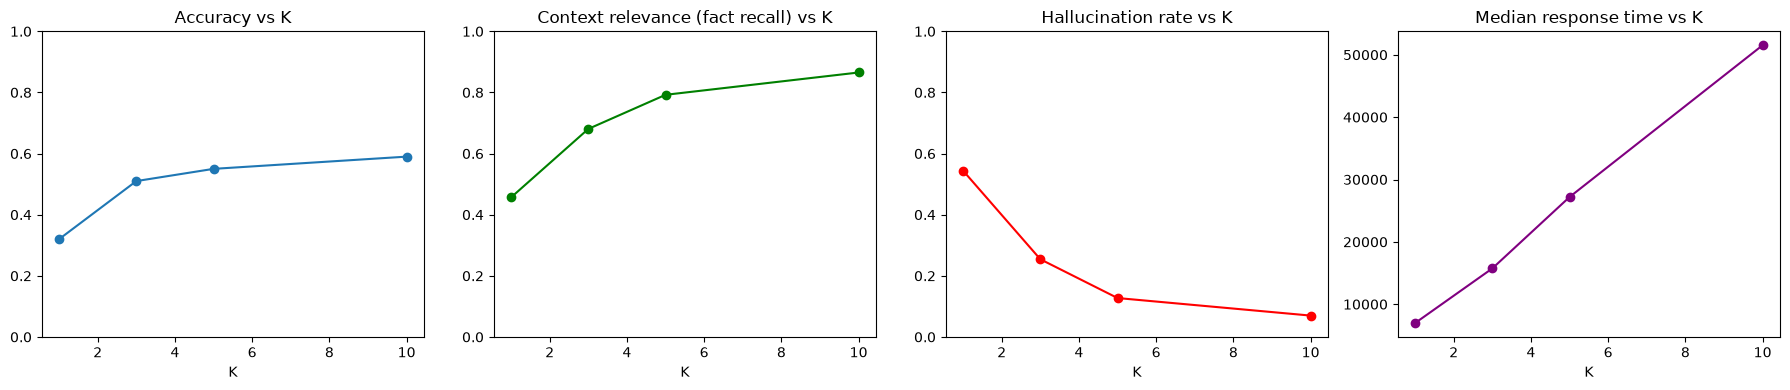

In [5]:
k_rows = comparison[comparison["condition"].isin(["k1", "k3", "k5", "k10"])].copy()
k_rows["k"] = k_rows["k"].astype(int)
k_rows = k_rows.sort_values("k")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].plot(k_rows["k"], k_rows["accuracy_normalised_mean"], marker="o")
axes[0].set_title("Accuracy vs K"); axes[0].set_xlabel("K"); axes[0].set_ylim(0, 1)
axes[1].plot(k_rows["k"], k_rows["context_fact_recall_mean"], marker="o", color="green")
axes[1].set_title("Context relevance (fact recall) vs K"); axes[1].set_xlabel("K"); axes[1].set_ylim(0, 1)
axes[2].plot(k_rows["k"], k_rows["hallucination_rate"], marker="o", color="red")
axes[2].set_title("Hallucination rate vs K"); axes[2].set_xlabel("K"); axes[2].set_ylim(0, 1)
axes[3].plot(k_rows["k"], k_rows["total_ms_median"], marker="o", color="purple")
axes[3].set_title("Median response time vs K"); axes[3].set_xlabel("K")
fig.tight_layout()
plt.show()

**Observed (see `results/figures/` for the saved versions of these exact charts):**

- Accuracy rises sharply from K=1 to K=3, then flattens toward K=10 — diminishing returns, not a
  monotonic "more is always better" curve.
- Context relevance (fact recall) and the lexically-supported claim rate both increase monotonically
  with K for this dataset — more retrieved evidence reduced the model's unsupported claims here.
- Response time grows close to linearly with K, since prompt length (and therefore generation cost)
  scales with the number of retrieved chunks.

## Statistical significance (paired Wilcoxon signed-rank, Holm-corrected)

In [6]:
tests = pd.DataFrame(paired_tests(records, CONDITION_ORDER))
tests[(tests["metric"] == "accuracy_score") & (tests["p_holm"].notna())].sort_values("p_holm")

,metric,a,b,n,mean_a,mean_b,mean_diff_b_minus_a,p_value,note,p_holm
7,accuracy_score,k1,k10,50,0.64,1.18,0.54,0.000036,None,0.000540
6,accuracy_score,k1,k5,50,0.64,1.10,0.46,0.000221,None,0.003094
5,accuracy_score,k1,k3,50,0.64,1.02,0.38,0.001091,None,0.014183
3,accuracy_score,no_rag,k10,50,0.74,1.18,0.44,0.001672,None,0.020064
4,accuracy_score,no_rag,gold,25,0.88,1.44,0.56,0.007196,None,0.079156
2,accuracy_score,no_rag,k5,50,0.74,1.10,0.36,0.009750,None,0.097500
1,accuracy_score,no_rag,k3,50,0.74,1.02,0.28,0.047422,None,0.393039
8,accuracy_score,k1,gold,25,0.96,1.44,0.48,0.043671,None,0.393039
10,accuracy_score,k3,k10,50,1.02,1.18,0.16,0.096831,None,0.677817
0,accuracy_score,no_rag,k1,50,0.74,0.64,-0.10,0.424832,None,1.000000


## Reproducing `results/results.csv` and `results/comparison_table.csv`

The CSV/figure export itself lives in `scripts/export_results.py` (kept as a script, not duplicated
here, so there is a single source of truth):

```bash
.venv/bin/python scripts/export_results.py --run-id full-50q-2026-10-12
.venv/bin/python scripts/build_presentation.py
```